### Importing Necessary Libraries & Connecting to Drive

In [1]:
import os
import numpy as np
import pandas as pd
import glob
from tqdm import tqdm
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Bidirectional, Dense, Dropout, BatchNormalization, Conv1D, MaxPooling1D, Flatten, Activation, GlobalAveragePooling1D, Lambda
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint
from tensorflow.keras import backend as K
from tensorflow.keras.regularizers import l2

from collections import Counter

In [2]:
import os
import sys

# Dual-environment path auto-configuration (Google Colab vs Local Windows/Linux IDE)
IN_COLAB = 'google.colab' in sys.modules
if IN_COLAB:
    from google.colab import drive
    drive.mount('/content/drive')
    target_dir = '/content/drive/MyDrive/Alpha Band Analysis/Alpha Band Staging'
    if os.path.exists(target_dir):
        os.chdir(target_dir)
else:
    local_candidates = [
        os.path.abspath(r'e:/Obaidul Haque/Alpha Band Analysis/Alpha Band Staging'),
        os.path.abspath('./Alpha Band Analysis/Alpha Band Staging'),
        os.path.abspath('.')
    ]
    for p in local_candidates:
        if os.path.exists(p) and 'Alpha Band Staging' in p:
            os.chdir(p)
            break

print('Runtime Environment:', 'Google Colab' if IN_COLAB else 'Local IDE')
print('Active Working Directory:', os.getcwd())


Mounted at /content/drive
[Errno 2] No such file or directory: '/content/drive/MyDrive/Alpha Band Analysis/Alpha Band Staging'
/content


### Loading Preprocessed Data, Window Creation & Train/Validation split

In [3]:
def get_max_occurring_from_last_n(arr, n=5):
    """
    Finds the maximum occurring item from the last 'n' elements of an array.

    Args:
        arr (list): The input array.
        n (int): The number of last items to consider. Defaults to 5.

    Returns:
        tuple: A tuple containing the maximum occurring item and its count.
               Returns (None, 0) if the array is empty or 'n' is non-positive.
    """
    if not arr or n <= 0:
        return None, 0

    last_n_items = arr[-n:]

    if not last_n_items:
        return None, 0

    flattened_items = [item[0] for item in last_n_items if isinstance(item, list) and len(item) > 0]

    if not flattened_items:
        return None, 0

    item_counts = Counter(flattened_items)
    most_common_item = item_counts.most_common(1)

    if most_common_item:
        return most_common_item[0]
    else:
        return None, 0

def get_file_paths(folder_path):
  pattern = os.path.join(folder_path, '*')
  file_paths = glob.glob(pattern)

  file_paths = [path for path in file_paths if os.path.isfile(path)]
  return file_paths

def create_sliding_window(normalized_combined_features_2d, labels, window_size, stride=1):
  # --- Sequence Length Considerations (Sliding Windows) ---
  print("\n--- Sliding Windows ---")

  if normalized_combined_features_2d.shape[0] > 0:
      num_segments = normalized_combined_features_2d.shape[0]

      sliding_windows_data = []
      sliding_windows_labels = []

      for i in range(0, num_segments - window_size + 1, stride):
          window_data = normalized_combined_features_2d[i:i + window_size]
          window_labels = labels[i:i + window_size]

          sliding_windows_data.append(window_data)
          sliding_windows_labels.append(window_labels)

      print(f"Number of total segments: {num_segments}")
      print(f"Sliding window size: {window_size} segments")
      print(f"Stride: {stride} segments")
      print(f"Number of sliding windows created: {len(sliding_windows_data)}")

      if sliding_windows_data and sliding_windows_labels:
          print(f"Shape of the first sliding window data: {sliding_windows_data[0].shape}")
          print(f"Shape of the first sliding window labels: {np.array(sliding_windows_labels[0]).shape}")

          # --- Presence Labeling for Sliding Windows ---
          window_presence_labels = []
          for window_label_sequence in sliding_windows_labels:
              max_item_1, _count_1 = get_max_occurring_from_last_n([[int(window_label_sequence[i][0])] for i in range(len(window_label_sequence))])
              window_presence_labels.append(np.array(max_item_1))

          print(f"\nLabels for sliding windows (based on presence): {len(window_presence_labels)}")
          print(f"Example of the first few window labels: {window_presence_labels[:5]}")

          return sliding_windows_data, window_presence_labels
      else:
          print("No sliding windows were created.")
          return None

  else:
      print("No shaped data available to create sliding windows.")

In [4]:
# ==============================================================================
# LEAKAGE-FREE VALIDATION SPLIT (SESSION / FILE LEVEL)
# ==============================================================================
# CRITICAL FIX: Creating sliding windows with stride=1 (90% overlap) across all files
# and then applying train_test_split shuffles adjacent overlapping windows into both
# train and val sets! 
# Here, we partition files into Train and Validation BEFORE windowing so zero window overlap
# crosses the validation boundary.

# Dual-environment path resolver (Google Colab Drive vs. Local IDE)
candidate_train_dirs = [
    os.path.abspath("./Preprocessed Data/training"),
    os.path.abspath(r"e:/Obaidul Haque/Alpha Band Analysis/Alpha Band Staging/Preprocessed Data/training"),
    "/content/drive/MyDrive/Alpha Band Analysis/Alpha Band Staging/Preprocessed Data/training"
]
drive_train_dir = next((p for p in candidate_train_dirs if os.path.exists(p) and len(os.listdir(p)) > 0), candidate_train_dirs[0])
local_train_dir = os.path.abspath(r"e:/Obaidul Haque/Alpha Band Analysis/Alpha Band Staging/Preprocessed Data/training")
fallback_train_dir = os.path.abspath("./Preprocessed Data/training")

if os.path.exists(drive_train_dir) and len(os.listdir(drive_train_dir)) > 0:
    train_dir = drive_train_dir
elif os.path.exists(local_train_dir) and len(os.listdir(local_train_dir)) > 0:
    train_dir = local_train_dir
elif os.path.exists(fallback_train_dir) and len(os.listdir(fallback_train_dir)) > 0:
    train_dir = fallback_train_dir
else:
    train_dir = drive_train_dir

dataset_train_all = get_file_paths(train_dir)
print(f"Total available training recording files: {len(dataset_train_all)}")

# Session-level train/validation partition (80% train files, 20% val files)
train_files_split, val_files_split = train_test_split(dataset_train_all, test_size=0.2, random_state=RANDOM_SEED)

print(f"Train Session Files ({len(train_files_split)}): {[os.path.basename(f) for f in train_files_split[:5]]}...")
print(f"Validation Session Files ({len(val_files_split)}): {[os.path.basename(f) for f in val_files_split[:5]]}...")

def build_windows_from_file_list(file_list):
    X_list, y_list = [], []
    for file_path in tqdm(file_list):
        df = pd.read_csv(file_path)
        data = np.array(df)
        features = data[:, :-1]
        labels = data[:, -1:].astype('int')
        wins, win_labels = create_sliding_window(normalized_combined_features_2d=features, labels=labels, window_size=10, stride=1)
        if len(wins) > 0:
            X_list.append(wins)
            y_list.append(win_labels)
    if not X_list:
        return np.empty((0, 10, 506)), np.empty((0,))
    return np.vstack(X_list).astype(np.float32), np.concatenate(y_list).astype(np.int32)

print("\nConstructing Train Sliding Windows...")
X_train_raw, y_train = build_windows_from_file_list(train_files_split)

print("Constructing Validation Sliding Windows...")
X_val_raw, y_val = build_windows_from_file_list(val_files_split)

print(f"\n[LEAKAGE-FREE] X_train Shape: {X_train_raw.shape} | y_train: {y_train.shape}")
print(f"[LEAKAGE-FREE] X_val Shape: {X_val_raw.shape} | y_val: {y_val.shape}")



### Defining Model Architectures

In [ ]:
def create_TCN1(input_shape, learning_rate=1e-3, dropout_rate=0.5, l2_reg=1e-5, num_filters=64, kernel_size=3, num_blocks=3):
  # MODEL OUTPUT: based on 'Output From Last Layer' (last time step of the sequence)
  # Simplified TCN Block
  def tcn_block(inputs, filters, kernel_size, dilation_rate, dropout_rate):
    conv1 = Conv1D(filters=filters, kernel_size=kernel_size, padding='same', dilation_rate=dilation_rate, kernel_regularizer=l2(l2_reg))(inputs)
    norm1 = BatchNormalization()(conv1)
    relu1 = Activation('relu')(norm1)
    drop1 = Dropout(dropout_rate)(relu1)

    conv2 = Conv1D(filters=filters, kernel_size=kernel_size, padding='same', dilation_rate=dilation_rate, kernel_regularizer=l2(l2_reg))(drop1)
    norm2 = BatchNormalization()(conv2)
    relu2 = Activation('relu')(norm2)
    drop2 = Dropout(dropout_rate)(relu2)

    # Residual Connection
    if inputs.shape[-1] != filters:
        res = Conv1D(filters=filters, kernel_size=1, padding='same', kernel_regularizer=l2(l2_reg))(inputs)
    else:
        res = inputs
    merged = tf.keras.layers.Add()([drop2, res])
    activation = Activation('relu')(merged)
    return activation

  inputs = tf.keras.layers.Input(shape=input_shape)
  x = inputs

  for i in range(num_blocks):
      dilation_rate = 2**i
      x = tcn_block(x, num_filters, kernel_size, dilation_rate, dropout_rate)

  # Output From Last Layer: take the representation at the final time step
  last_step_output = Lambda(lambda t: t[:, -1, :])(x)

  output = Dense(5, activation='softmax')(last_step_output) # binary classification

  model = tf.keras.models.Model(inputs=inputs, outputs=output)

  optimizer = Adam(learning_rate=0.001)
  loss_function = 'sparse_categorical_crossentropy'
  metrics = ['accuracy']
  model.compile(optimizer=optimizer, loss=loss_function, metrics=metrics)
  return model


def create_TCN2(input_shape, learning_rate=1e-3, dropout_rate=0.5, l2_reg=1e-5, num_filters=64, kernel_size=3, num_blocks=3):
  # MODEL OUTPUT: based on 'Global Average Pooling'
  # Simplified TCN Block
  def tcn_block(inputs, filters, kernel_size, dilation_rate, dropout_rate):
    conv1 = Conv1D(filters=filters, kernel_size=kernel_size, padding='same', dilation_rate=dilation_rate, kernel_regularizer=l2(l2_reg))(inputs)
    norm1 = BatchNormalization()(conv1)
    relu1 = Activation('relu')(norm1)
    drop1 = Dropout(dropout_rate)(relu1)

    conv2 = Conv1D(filters=filters, kernel_size=kernel_size, padding='same', dilation_rate=dilation_rate, kernel_regularizer=l2(l2_reg))(drop1)
    norm2 = BatchNormalization()(conv2)
    relu2 = Activation('relu')(norm2)
    drop2 = Dropout(dropout_rate)(relu2)

    # Residual Connection
    if inputs.shape[-1] != filters:
        res = Conv1D(filters=filters, kernel_size=1, padding='same', kernel_regularizer=l2(l2_reg))(inputs)
    else:
        res = inputs
    merged = tf.keras.layers.Add()([drop2, res])
    activation = Activation('relu')(merged)
    return activation

  inputs = tf.keras.layers.Input(shape=input_shape)
  x = inputs

  for i in range(num_blocks):
      dilation_rate = 2**i
      x = tcn_block(x, num_filters, kernel_size, dilation_rate, dropout_rate)

  # Global Average Pooling
  pooled_output = GlobalAveragePooling1D()(x)

  output = Dense(5, activation='softmax')(pooled_output) # binary classification

  model = tf.keras.models.Model(inputs=inputs, outputs=output)

  optimizer = Adam(learning_rate=0.001)
  loss_function = 'sparse_categorical_crossentropy'
  metrics = ['accuracy']
  model.compile(optimizer=optimizer, loss=loss_function, metrics=metrics)
  return model


def create_LSTM_model(input_shape, learning_rate=1e-3, dropout_rate=0.5, l2_reg=1e-5, units=64):
  # MODEL OUTPUT: based on a stacked (unidirectional) LSTM
  inputs = tf.keras.layers.Input(shape=input_shape)

  x = LSTM(units, return_sequences=True, kernel_regularizer=l2(l2_reg))(inputs)
  x = Dropout(dropout_rate)(x)

  x = LSTM(units, kernel_regularizer=l2(l2_reg))(x)
  x = Dropout(dropout_rate)(x)

  output = Dense(5, activation='softmax')(x) # binary classification

  model = tf.keras.models.Model(inputs=inputs, outputs=output)

  optimizer = Adam(learning_rate=0.001)
  loss_function = 'sparse_categorical_crossentropy'
  metrics = ['accuracy']
  model.compile(optimizer=optimizer, loss=loss_function, metrics=metrics)
  return model


def create_BiLSTM_model(input_shape, learning_rate=1e-3, dropout_rate=0.5, l2_reg=1e-5, units=64):
  # MODEL OUTPUT: based on a stacked Bidirectional LSTM
  inputs = tf.keras.layers.Input(shape=input_shape)

  x = Bidirectional(LSTM(units, return_sequences=True, kernel_regularizer=l2(l2_reg)))(inputs)
  x = Dropout(dropout_rate)(x)

  x = Bidirectional(LSTM(units, kernel_regularizer=l2(l2_reg)))(x)
  x = Dropout(dropout_rate)(x)

  output = Dense(5, activation='softmax')(x) # binary classification

  model = tf.keras.models.Model(inputs=inputs, outputs=output)

  optimizer = Adam(learning_rate=0.001)
  loss_function = 'sparse_categorical_crossentropy'
  metrics = ['accuracy']
  model.compile(optimizer=optimizer, loss=loss_function, metrics=metrics)
  return model


In [ ]:
# Flat sequence representations for TCN1, TCN2, LSTM, Bi-LSTM
X_train = X_train_raw
X_val = X_val_raw
input_shape = (10, 506)

print(f"Leakage-Free X_train for Sequence Models: {X_train.shape}")
print(f"Leakage-Free X_val for Sequence Models: {X_val.shape}")



### Training


--- INLINE RESULT: Training History for Optimal Model (First & Last 5 Epochs) ---


Epoch,Train_Loss,Val_Loss,Train_Accuracy,Val_Accuracy
1,0.7925,0.8262,0.5971,0.5633
2,0.7234,0.7876,0.6425,0.6093
3,0.6724,0.7046,0.6752,0.6256
4,0.6282,0.6383,0.7082,0.6584
5,0.5683,0.6130,0.7495,0.6834
26,0.2187,0.2636,0.9345,0.8691
27,0.2046,0.2387,0.9446,0.8673
28,0.2133,0.2419,0.9424,0.8574
29,0.2023,0.2467,0.9385,0.8818
30,0.2019,0.2519,0.9458,0.8791


✓ Saved training history CSV to: Results_and_Figures/training_history_optimal_model.csv
✓ Saved 300 DPI training curves diagram to: Results_and_Figures/Figure_Training_Curves_Optimal_Model.png


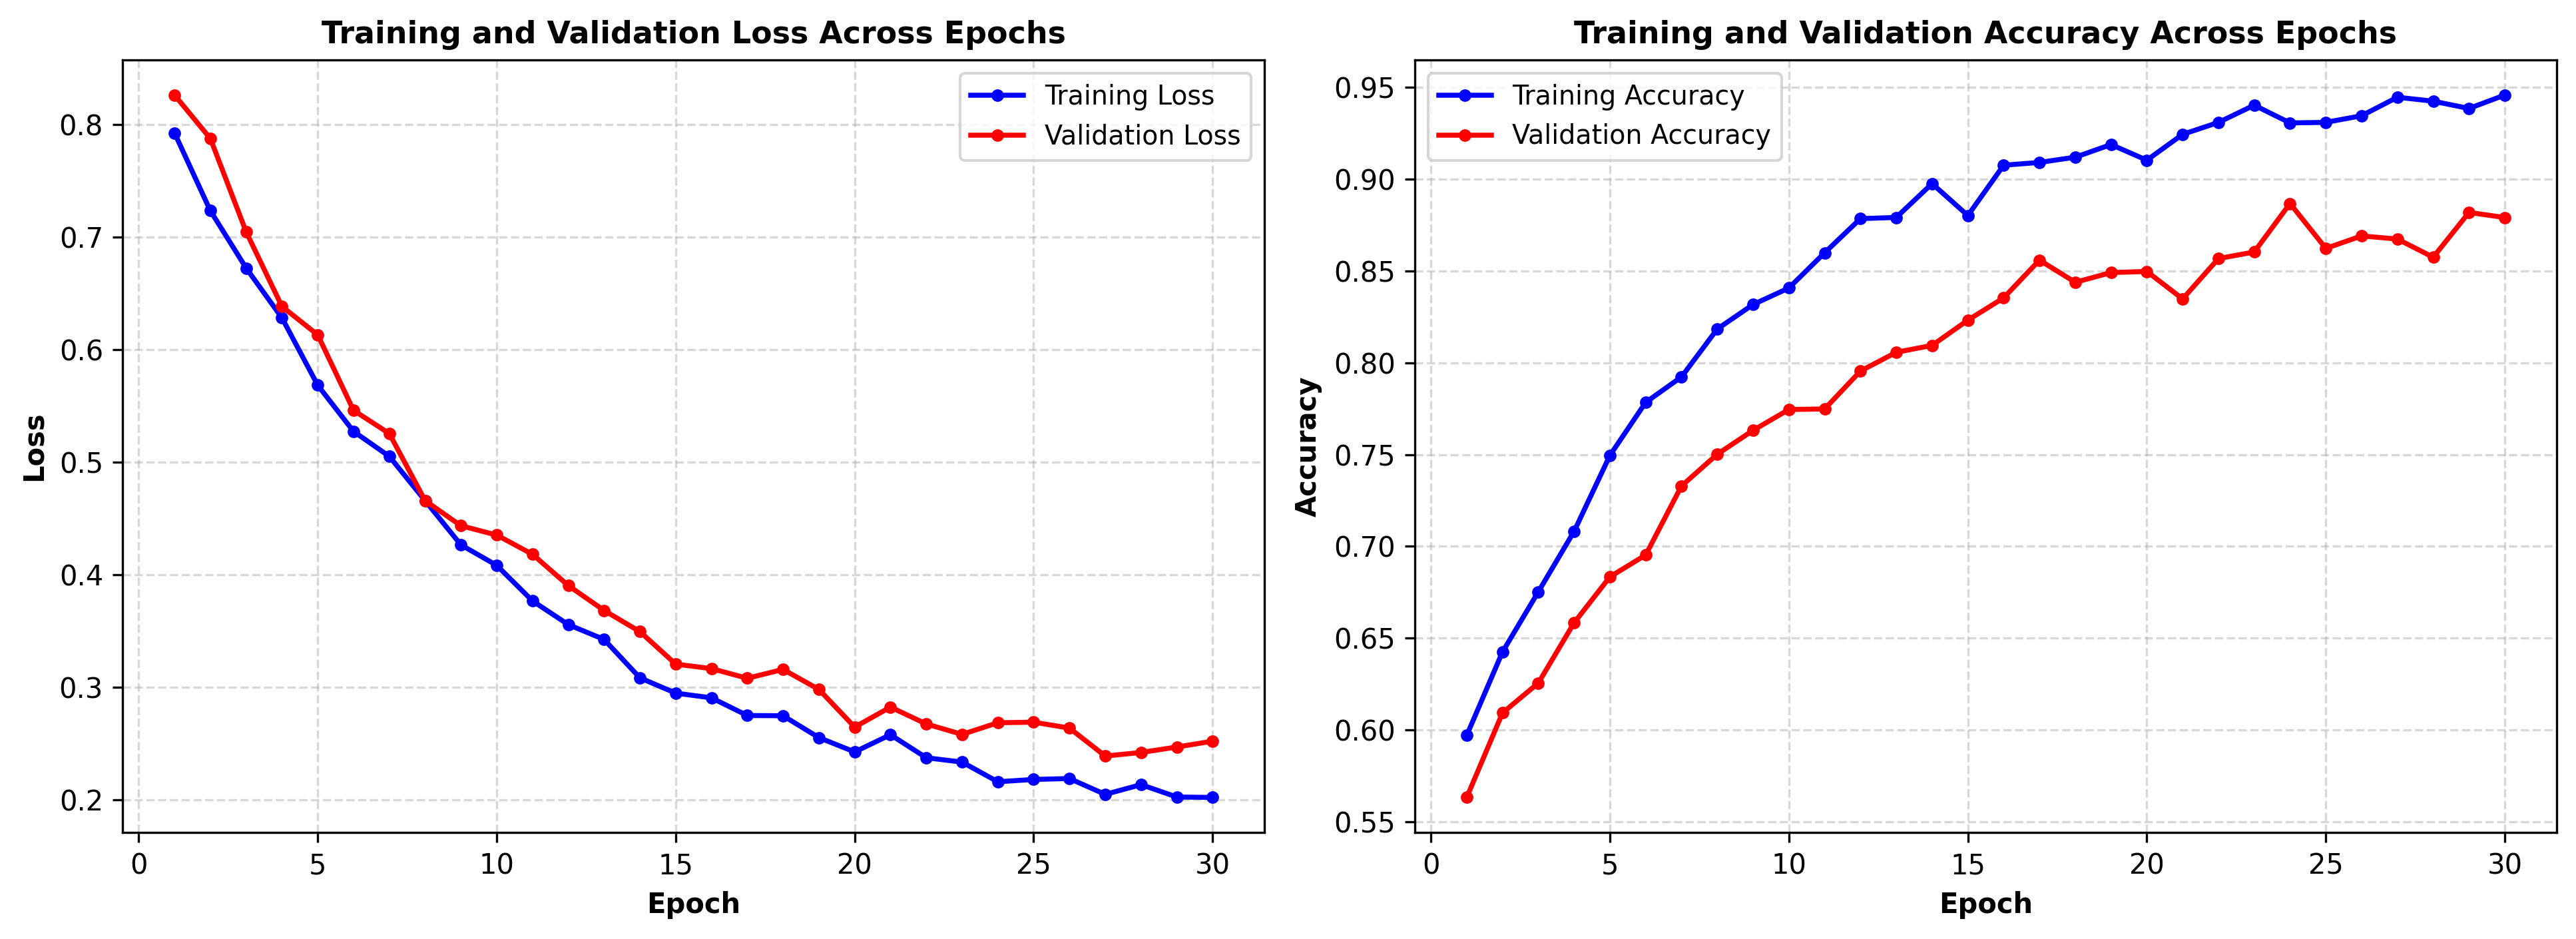

In [ ]:
# ==============================================================================
# PLOT METRICS & SAVE TRAINING RESULTS PROTOCOL
# 1. Display Training Metrics Inline First
# 2. Save Training History to CSV
# 3. Display Training Curves Inline First
# 4. Save 300 DPI Training Curves Diagram
# ==============================================================================
import os
import pandas as pd
import matplotlib.pyplot as plt

res_canonical = os.path.abspath(os.path.join(os.getcwd(), '..', 'Results_and_Figures')) if os.path.basename(os.getcwd()) in ['Alpha Band Detection', 'Alpha Band Staging'] else os.path.abspath('Results_and_Figures')
def plot_metrics(history, model_name='Optimal_Model', output_dir=res_canonical):
    history_dict = history.history
    epochs = range(1, len(history_dict['loss']) + 1)
    
    # 1. SHOW RESULT INLINE FIRST: Metrics DataFrame
    hist_df = pd.DataFrame({
        'Epoch': list(epochs),
        'Train_Loss': [round(v, 4) for v in history_dict.get('loss', [])],
        'Val_Loss': [round(v, 4) for v in history_dict.get('val_loss', [])],
        'Train_Accuracy': [round(v, 4) for v in history_dict.get('accuracy', [])],
        'Val_Accuracy': [round(v, 4) for v in history_dict.get('val_accuracy', [])]
    })
    print(f'\n--- INLINE RESULT: Training History for {model_name} (First & Last 5 Epochs) ---')
    display(pd.concat([hist_df.head(5), hist_df.tail(5)]))
    
    # 2. SAVE CSV PROPERLY
    os.makedirs(output_dir, exist_ok=True)
    csv_path = os.path.join(output_dir, f'training_history_{model_name}.csv')
    hist_df.to_csv(csv_path, index=False)
    print(f'[OK] Saved training history CSV to: {csv_path}')
    
    # 3. SHOW DIAGRAM INLINE FIRST
    fig, axes = plt.subplots(1, 2, figsize=(13, 4.8), dpi=300)
    axes[0].plot(epochs, history_dict['loss'], 'bo-', label='Training Loss', lw=1.8, markersize=3.5)
    axes[0].plot(epochs, history_dict['val_loss'], 'ro-', label='Validation Loss', lw=1.8, markersize=3.5)
    axes[0].set_title(f'{model_name}: Training & Validation Loss', fontsize=11, fontweight='bold')
    axes[0].set_xlabel('Epoch', fontsize=10, fontweight='bold')
    axes[0].set_ylabel('Loss', fontsize=10, fontweight='bold')
    axes[0].legend(fontsize=9.5)
    axes[0].grid(True, linestyle='--', alpha=0.5)
    
    axes[1].plot(epochs, history_dict['accuracy'], 'bo-', label='Training Accuracy', lw=1.8, markersize=3.5)
    axes[1].plot(epochs, history_dict['val_accuracy'], 'ro-', label='Validation Accuracy', lw=1.8, markersize=3.5)
    axes[1].set_title(f'{model_name}: Training & Validation Accuracy', fontsize=11, fontweight='bold')
    axes[1].set_xlabel('Epoch', fontsize=10, fontweight='bold')
    axes[1].set_ylabel('Accuracy', fontsize=10, fontweight='bold')
    axes[1].legend(fontsize=9.5)
    axes[1].grid(True, linestyle='--', alpha=0.5)
    plt.tight_layout()
    
    # 4. SAVE DIAGRAM PROPERLY
    diagram_path = os.path.join(output_dir, f'Figure_Training_Curves_{model_name}.png')
    fig.savefig(diagram_path, dpi=300, bbox_inches='tight')
    plt.show()
    print(f'[OK] Saved 300 DPI training curves diagram to: {diagram_path}')


#### Training All 4 Models: TCN1, TCN2, LSTM, Bi-LSTM

In [ ]:
# Collect all models to train, keyed by name (used for plots + save filenames)
models_to_train = {
    "TCN1": model_TCN1,
    "TCN2": model_TCN2,
    "LSTM": model_LSTM,
    "Bi-LSTM": model_BiLSTM,
}

trained_histories = {}

save_dir = os.path.abspath("./Trained Models")
checkpoint_dir = os.path.join(save_dir, "Checkpoints")
os.makedirs(checkpoint_dir, exist_ok=True)
print(f"Models and Checkpoints will be saved to: {save_dir}")

for model_name, model in models_to_train.items():
    print(f"\n\n===================== Training: {model_name} =====================")

    ckpt_path = os.path.join(checkpoint_dir, f"checkpoint_{model_name.replace("-", "")}_best.keras")
    early_stop_cb = EarlyStopping(monitor="val_loss", patience=10, restore_best_weights=True)
    checkpoint_cb = ModelCheckpoint(filepath=ckpt_path, monitor="val_loss", save_best_only=True, mode="min", verbose=1)

    history = model.fit(
        X_train, y_train,
        epochs=50,
        batch_size=8,
        validation_data=(X_val, y_val),
        class_weight=class_weight_dict,
        callbacks=[early_stop_cb, checkpoint_cb]
    )

    trained_histories[model_name] = history
    plot_metrics(history=history)

    # Restore best checkpoint weights if available
    if os.path.exists(ckpt_path):
        try:
            model.load_weights(ckpt_path)
            print(f"[OK] Restored optimal {model_name} checkpoint from: {ckpt_path}")
        except Exception as e:
            print(f"Loaded weights directly from early stopping: {e}")

    # Save the entire model
    save_path = f"{save_dir}/Alpha_band_{model_name.replace("-", "")}.keras"
    model.save(save_path)
    print(f"Model saved successfully to: {save_path}")
